In [1]:
# 从高德地图获取数据并分析
# 完成时间：2026-7-20
# 练习内容：从高德开放平台获取数据，将数据解析处理后再实现批量处理

开始抓行政区划

In [2]:
import requests
import json

url = 'https://restapi.amap.com/v3/config/district' # 高德地图行政区划查询接口的官方服务地址

# 构造请求参数字典（ API 的参数名、取值、必填规则可在行政规划查询文档中找到）
dict1 = {
    'subdistrict': '3', # 子行政区返回层级，数字 3 表示最多返回下 3 级区划（比如省 - 市 - 区 - 街道）
    'showbiz': 'false', # 是否返回商圈数据，false 表示只返回标准行政区划，不包含商圈信息
    'extensions': 'all', # 返回结果的详细程度，all 表示返回完整信息，包含行政区边界坐标（polyline）；如果填 base 只会返回名称、编码等基础信息，没有边界数据
    'key': '001a743b8f127d392da83cfdd66f5e8e', # 高德开放平台个人申请的密钥
    'keywords': '罗湖区', # 查询的行政区关键词，支持中文名、城市编码、adcode 等多种写法
    'output': 'json' # 指定服务器返回的数据格式为 JSON，方便程序解析处理
}

# 发送get请求并接收响应
response = requests.get(url, params=dict1)

# 解析 JSON 响应数据
result = response.json()
# .json():把服务器返回的字节内容按 UTF-8 解码成字符串;把 JSON 格式的字符串转换成 Python 原生的「字典 + 列表」嵌套结构

In [3]:
"""
result（字典）
└── districts（列表，存放匹配到的所有行政区）
    └── 第0个元素（字典，你查询的“罗湖区”主结果）
        ├── name：行政区名称
        ├── adcode：行政区编码
        └── polyline：边界坐标字符串（核心数据）
"""

'\nresult（字典）\n└── districts（列表，存放匹配到的所有行政区）\n    └── 第0个元素（字典，你查询的“罗湖区”主结果）\n        ├── name：行政区名称\n        ├── adcode：行政区编码\n        └── polyline：边界坐标字符串（核心数据）\n'

行政区划边界线型数据提取

In [4]:
# 提取原始 polyline 字符串
polyline_str = result['districts'][0]['polyline']
# result['districts']:从最外层字典里取出 districts 键对应的值，它是一个列表,因为我们查询的是 “罗湖区”，匹配结果只有 1 个，所以列表里只有 1 个元素
# [0]:取列表的第 1 个元素,也就是罗湖区行政区数据，这是一个字典
# ['polyline']:从行政区字典里取出 polyline 键对应的值，最终得到一长串坐标字符串。
"""
polyline 字符串的格式规则
单个多边形内部，坐标点之间用 分号 ; 分隔
每个坐标点内部，经度和纬度用 逗号 , 分隔
如果行政区由多个面组成（比如有飞地、岛屿），多个多边形之间用 竖线 | 分隔
eg:114.1,22.5;114.2,22.5;114.2,22.6|114.3,22.7;114.4,22.7  代表 2 个多边形，第一个有 3 个坐标点，第二个有 2 个坐标
"""

'\npolyline 字符串的格式规则\n单个多边形内部，坐标点之间用 分号 ; 分隔\n每个坐标点内部，经度和纬度用 逗号 , 分隔\n如果行政区由多个面组成（比如有飞地、岛屿），多个多边形之间用 竖线 | 分隔\neg:114.1,22.5;114.2,22.5;114.2,22.6|114.3,22.7;114.4,22.7  代表 2 个多边形，第一个有 3 个坐标点，第二个有 2 个坐标\n'

In [5]:
# 先处理多面情况：用竖线拆分所有多边形，再统一拼接所有坐标点
all_points_str = polyline_str.replace('|', ';')
# replace(old,new,count(替换的最大次数))

# 用分号拆分，把一长串字符串拆分成列表，列表里每个元素都是一个 “经度，纬度” 格式的字符串
point_list = all_points_str.split(';')
# split(sep(分割符，指定按什么字符切割),maxsplit(最大切割次数，默认-1，表示切割所有匹配的位置))

# 遍历每个点，拆分经纬度，转成浮点数，存成二维列表
coord_list = []
for point in point_list:
    lon_str, lat_str = point.split(',')
    coord_list.append([float(lon_str), float(lat_str)]) # 单个点用逗号拆分，分别得到字符串格式的经度和纬度
    
# 转成 pandas DataFrame，设置列名
import pandas as pd
polyline_df = pd.DataFrame(coord_list, columns=['lon_lst', 'lat_lst'])

# 查看前5行
polyline_df.head()

"""
补充更简洁的写法
import numpy as np
import pandas as pd

# 拆分+转浮点+重塑形状
all_points = np.array(polyline_str.replace('|',';').replace(';',',').split(',')).astype(float)
coord_array = all_points.reshape(-1, 2)
polyline_df = pd.DataFrame(coord_array, columns=['lon_lst', 'lat_lst'])
"""

"\n补充更简洁的写法\nimport numpy as np\nimport pandas as pd\n\n# 拆分+转浮点+重塑形状\nall_points = np.array(polyline_str.replace('|',';').replace(';',',').split(',')).astype(float)\ncoord_array = all_points.reshape(-1, 2)\npolyline_df = pd.DataFrame(coord_array, columns=['lon_lst', 'lat_lst'])\n"

坐标转换

In [6]:
# 高德、腾讯等国内地图的坐标都经过了 GCJ-02 加密（俗称火星坐标），而我们常用的 GPS 设备、QGIS、ArcGIS、GeoJSON 标准默认都是 WGS84 坐标系，因此必须转换才能通用
# 官方公开了「WGS84 转 GCJ-02」的加密公式，逆转换是通过近似迭代法反向推算
import math

# 定义地理常量
PI = 3.1415926535897932384626
a = 6378245.0
ee = 0.00669342162296594323

# 判断坐标是否在中国境外，境外不做偏移
def out_of_china(lng, lat):
    if lng < 72.004 or lng > 137.8347:
        return True
    if lat < 0.8293 or lat > 55.8271:
        return True
    return False

# 计算纬度方向的偏移量
def transform_lat(lng, lat):
    ret = -100.0 + 2.0 * lng + 3.0 * lat + 0.2 * lat * lat + 0.1 * lng * lat + 0.2 * math.sqrt(abs(lng))
    ret += (20.0 * math.sin(6.0 * lng * PI) + 20.0 * math.sin(2.0 * lng * PI)) * 2.0 / 3.0
    ret += (20.0 * math.sin(lat * PI) + 40.0 * math.sin(lat / 3.0 * PI)) * 2.0 / 3.0
    ret += (160.0 * math.sin(lat / 12.0 * PI) + 320 * math.sin(lat * PI / 30.0)) * 2.0 / 3.0
    return ret

# 计算经度方向的偏移量
def transform_lng(lng, lat):
    ret = 300.0 + lng + 2.0 * lat + 0.1 * lng * lng + 0.1 * lng * lat + 0.1 * math.sqrt(abs(lng))
    ret += (20.0 * math.sin(6.0 * lng * PI) + 20.0 * math.sin(2.0 * lng * PI)) * 2.0 / 3.0
    ret += (20.0 * math.sin(lng * PI) + 40.0 * math.sin(lng / 3.0 * PI)) * 2.0 / 3.0
    ret += (150.0 * math.sin(lng / 12.0 * PI) + 300.0 * math.sin(lng / 30.0 * PI)) * 2.0 / 3.0
    return ret

# WGS84 转 GCJ-02（正转换，加密过程）
def wgs84_to_gcj02(lng, lat):
    if out_of_china(lng, lat):
        return lng, lat
    dlat = transform_lat(lng - 105.0, lat - 35.0)
    dlng = transform_lng(lng - 105.0, lat - 35.0)
    rad_lat = lat / 180.0 * PI
    magic = math.sin(rad_lat)
    magic = 1 - ee * magic * magic
    sqrt_magic = math.sqrt(magic)
    dlat = (dlat * 180.0) / ((a * (1 - ee)) / (magic * sqrt_magic) * PI)
    dlng = (dlng * 180.0) / (a / sqrt_magic * math.cos(rad_lat) * PI)
    mglat = lat + dlat
    mglng = lng + dlng
    return mglng, mglat

# GCJ-02 转 WGS84（逆转换，我们实际要用的）
def gcj02_to_wgs84(lng, lat):
    if out_of_china(lng, lat):
        return lng, lat
    dlat = transform_lat(lng - 105.0, lat - 35.0)
    dlng = transform_lng(lng - 105.0, lat - 35.0)
    rad_lat = lat / 180.0 * PI
    magic = math.sin(rad_lat)
    magic = 1 - ee * magic * magic
    sqrt_magic = math.sqrt(magic)
    dlat = (dlat * 180.0) / ((a * (1 - ee)) / (magic * sqrt_magic) * PI)
    dlng = (dlng * 180.0) / (a / sqrt_magic * math.cos(rad_lat) * PI)
    mglat = lat + dlat
    mglng = lng + dlng
    return lng * 2 - mglng, lat * 2 - mglat

In [7]:
# 定义单行转换函数
def convert_row(row): # row代表 DataFrame 的一整行数据
    lon_gcj = row['lon_lst'] # 从当前行里取出 GCJ-02 格式的经度值
    lat_gcj = row['lat_lst'] # 从当前行里取出 GCJ-02 格式的纬度值
    lon_wgs, lat_wgs = gcj02_to_wgs84(lon_gcj, lat_gcj) # 调用我们上面写的转换函数，把 GCJ-02 坐标转成 WGS84 坐标
    return pd.Series([lon_wgs, lat_wgs], index=['lon_lst', 'lat_lst']) # 把转换后的经纬度包装成 pandas 的 Series 对象，并指定列名，方便直接赋值回原表格

# 批量转换，覆盖原坐标列
polyline_df[['lon_lst', 'lat_lst']] = polyline_df.apply(convert_row, axis=1) # apply(..., axis=1)：表示按行遍历 DataFrame，把每一行都传给convert_row函数处理

# 查看转换结果
polyline_df.head()

,lon_lst,lat_lst
0,114.100060,22.534309
1,114.099691,22.535195
2,114.099657,22.537721
3,114.099640,22.537788
4,114.099655,22.537883


用线型生成geodataframe

<Axes: >

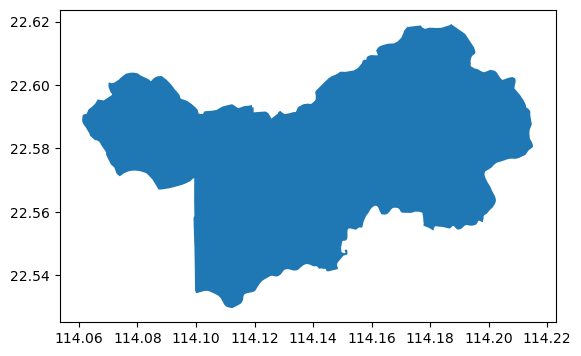

In [8]:
# 导入依赖库
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import geopandas
from shapely.geometry import Point, Polygon, shape

# 从坐标表格生成shapely多边形
district_polygon = Polygon(polyline_df.values)
# polyline_df.values：提取表格中的纯数值数据，返回一个numpy二维数组，数组形状为 (点数量, 2)，每一行对应一个坐标点，格式为 [经度, 纬度]，符合 Polygon 的输入格式要求
# Polygon(...)：shapely 的多边形构造函数，接收一组按边界顺序排列的坐标点，自动生成闭合的面几何对象。关键规则：点必须按边界的顺时针 / 逆时针顺序排列
# （高德返回的 polyline 本身就是有序边界，可直接使用）即使不手动闭合首尾点，Polygon 也会自动连接第一个点和最后一个点，
# 形成封闭的面生成的对象自带面积、边界、中心点等空间属性与计算方法

# 生成GeoDataFrame（空间数据框）
gdf = geopandas.GeoDataFrame(
    data=[{'name': '罗湖区'}],
    geometry=[district_polygon],
    crs="EPSG:4326"
)

# 绘制行政区边界
gdf.plot()

补充

In [9]:
# 一个行政区划由多个面（飞地、岛屿）组成时，坐标串中间以|分隔。如果直接把所有点拼接为一个 Polygon，会出现错误的跨区连线，应拆分后生成 MultiPolygon（多多边形）
from shapely.geometry import MultiPolygon

# 按竖线拆分原始polyline，每个部分单独生成Polygon
poly_parts = polyline_str.split('|')
polygon_list = []
for part in poly_parts:
    # 单个多边形解析为坐标元组列表
    points = [p.split(',') for p in part.split(';')]
    coords = [(float(lon), float(lat)) for lon, lat in points]
    polygon_list.append(Polygon(coords))

# 合并为多多边形对象
multi_poly = MultiPolygon(polygon_list)

# 保存
gdf.to_file(r'E:\GIS_Learning\output\luohuqu_Border.gpkg', driver='GPKG')